# 5 · Panel data models side by side: pooled, between, fixed, random and mixed effects
A compact, practical guide to the estimators used in notebooks 3 and 4, applied to two classic public panels shipped with `linearmodels`:

* **Wage panel** (Vella and Verbeek, 1998): 545 young men, 1980-1987. Does union membership raise wages?
* **Job training grants** (Holzer et al., 1993; Wooldridge's `JTRAIN`): Michigan manufacturing firms, 1987-1989. Did state training grants raise training hours?

Each section shows what the estimator assumes, what it identifies from, and how the answer changes.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
import statsmodels.formula.api as smf
from linearmodels.panel import PooledOLS, BetweenOLS, PanelOLS, RandomEffects, FirstDifferenceOLS, compare
from linearmodels.datasets import wage_panel, jobtraining
from effpanel import panel
wp = wage_panel.load().set_index(["nr", "year"], drop=False)
wp["const"] = 1.0
print(wp.shape, "|", wp.index.get_level_values(0).nunique(), "workers x", wp.year.nunique(), "years")
wp[["lwage", "union", "married", "exper", "expersq", "educ", "black", "hisp"]].describe().T[["mean", "std"]].round(3)

(4360, 13) | 545 workers x 8 years


,mean,std
lwage,1.649,0.533
union,0.244,0.430
married,0.439,0.496
exper,6.515,2.826
expersq,50.425,40.782
educ,11.767,1.746
black,0.116,0.320
hisp,0.156,0.363


## The same question, five estimators
* **Pooled OLS** ignores the panel structure.
* **Between** uses only differences *across* workers (person averages).
* **Fixed effects (within)** uses only changes *within* a worker over time. Time-invariant traits such as education and race are absorbed.
* **Random effects** is a weighted mix of between and within. It is efficient, but only valid if the individual effect is uncorrelated with the regressors.
* **First differences** uses year-to-year changes.

In [2]:
y = wp.lwage
X_all = wp[["const", "union", "married", "exper", "expersq", "educ", "black", "hisp"]]
X_tv = wp[["const", "union", "married", "expersq"]]
fits = {"Pooled OLS": PooledOLS(y, X_all).fit(cov_type="clustered", cluster_entity=True),
        "Between": BetweenOLS(y, X_all).fit(),
        "Random effects": RandomEffects(y, X_all).fit(cov_type="clustered", cluster_entity=True),
        "Fixed effects (two-way)": PanelOLS(y, X_tv, entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True),
        "First differences": FirstDifferenceOLS(y, wp[["union", "married", "expersq"]]).fit(cov_type="clustered", cluster_entity=True)}
union = pd.DataFrame({k: {"union premium": v.params["union"], "std err": v.std_errors["union"]} for k, v in fits.items()}).T
union["premium %"] = 100 * (np.exp(union["union premium"]) - 1)
union.round(4)

,union premium,std err,premium %
Pooled OLS,0.1801,0.0276,19.7304
Between,0.2707,0.0466,31.0851
Random effects,0.1074,0.0209,11.3356
Fixed effects (two-way),0.0800,0.0243,8.3289
First differences,0.0422,0.0220,4.3096


In [3]:
h = panel.hausman(wp, "lwage", ["union", "married", "exper", "expersq"])
print(f"robust Hausman (Mundlak) chi2({h['dof']}) = {h['chi2']:.1f}, p = {h['p_value']:.4f} -> prefer {h['preferred']}")
print(f"RE theta (weight on within variation): {fits['Random effects'].theta.mean().iloc[0]:.3f}")

robust Hausman (Mundlak) chi2(4) = 96.4, p = 0.0000 -> prefer Fixed effects
RE theta (weight on within variation): 0.643


## Mixed (multilevel) model: random intercepts *and* random slopes
`statsmodels` MixedLM lets the union premium itself vary across workers, which a fixed-effects model cannot do.

In [4]:
df = wp.reset_index(drop=True)
mm = smf.mixedlm("lwage ~ union + married + exper + expersq + educ + black + hisp", df, groups=df["nr"], re_formula="~union").fit(method="lbfgs")
print(mm.summary().tables[1].loc[["union", "educ"]])
sd_slope = np.sqrt(mm.cov_re.loc["union", "union"])
print(f"average union premium {mm.params['union']:.3f}; across-worker SD of the premium {sd_slope:.3f}")

       Coef. Std.Err.       z  P>|z| [0.025 0.975]
union  0.111    0.021   5.331  0.000  0.070  0.152
educ   0.101    0.009  11.179  0.000  0.083  0.119
average union premium 0.111; across-worker SD of the premium 0.193


## Policy evaluation with firm fixed effects: did training grants work?

In [5]:
jt = jobtraining.load().dropna(subset=["hrsemp"]).set_index(["fcode", "year"], drop=False)
jt["const"] = 1.0; jt["lemploy"] = np.log(jt.employ)
jt["d88"], jt["d89"] = (jt.year == 1988).astype(float), (jt.year == 1989).astype(float)
cols = ["const", "grant", "grant_1", "lemploy", "d88", "d89"]
jt = jt.dropna(subset=cols)
g = {"Pooled OLS": PooledOLS(jt.hrsemp, jt[cols]).fit(cov_type="clustered", cluster_entity=True),
     "Firm fixed effects": PanelOLS(jt.hrsemp, jt[cols], entity_effects=True, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)}
print(compare(g, stars=True))
fe = g["Firm fixed effects"]
print(f"grant effect with firm FE: +{fe.params['grant']:.1f} training hours per employee (95% CI {fe.conf_int().loc['grant', 'lower']:.1f} to {fe.conf_int().loc['grant', 'upper']:.1f})")

                     Model Comparison                    
                            Pooled OLS Firm fixed effects
---------------------------------------------------------
Dep. Variable                   hrsemp             hrsemp
Estimator                    PooledOLS           PanelOLS
No. Observations                   390                390
Cov. Est.                    Clustered          Clustered
R-squared                       0.2574             0.4909
R-Squared (Within)              0.4860             0.4909
R-Squared (Between)             0.1075             0.0481
R-Squared (Overall)             0.2574             0.2201
F-statistic                     26.617             48.206
P-value (F-stat)                0.0000             0.0000
=====================     ============        ===========
const                        25.356***             9.3250
                              (3.5787)           (0.5849)
grant                        31.971***          34.228***
              

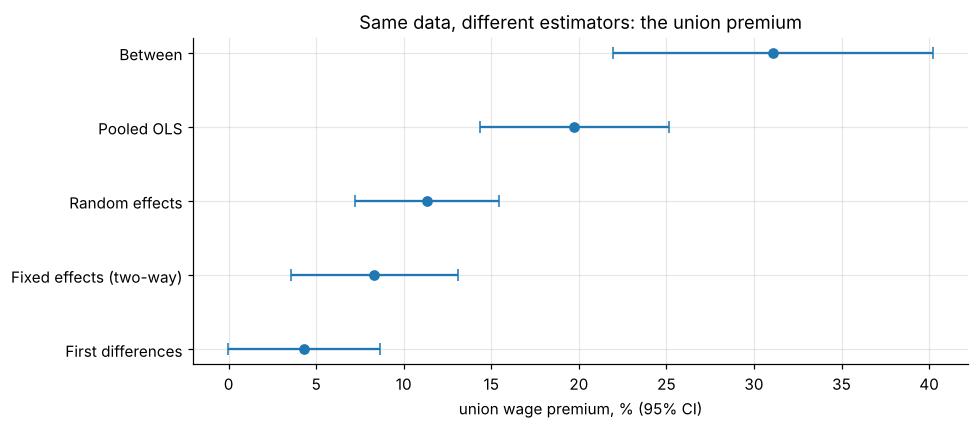

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
u = union.sort_values("premium %")
ax.errorbar(u["premium %"], range(len(u)), xerr=1.96 * 100 * u["std err"], fmt="o", capsize=4)
ax.set_yticks(range(len(u))); ax.set_yticklabels(u.index); ax.set_xlabel("union wage premium, % (95% CI)")
ax.set_title("Same data, different estimators: the union premium")
plt.tight_layout(); plt.savefig(IMG / "panel_estimators_union.png", bbox_inches="tight"); plt.show()

## Findings
* **The union wage premium depends on what variation you use.** Between workers it looks like 31%, pooled 20%, random effects 11%, fixed effects 8% and first differences 4%. Workers who join unions differ systematically from those who don't, so cross-sectional comparisons overstate the effect. The robust Hausman test (χ² = 96, p < 0.001) rejects random effects, so the within estimate (about 8%) is the credible one. First differences are lower again because year-to-year switches are noisier (more measurement error).
* **The premium is not the same for everyone.** A mixed model with a random union slope estimates an average of 0.11 log points but an across-worker standard deviation of 0.19, which a single fixed-effects coefficient hides.
* **Training grants worked, in the year they were received.** With firm fixed effects, a grant raised training by about 34 hours per employee (95% CI 27-42), close to the pooled estimate. The lagged grant has no effect, so the boost does not persist into the following year.
* **Practical rule:** use FE when the question is "what happens when X changes for the same unit" and the robust Hausman test rejects RE. Use RE or mixed models when time-invariant variables matter and the effects are plausibly uncorrelated with the regressors.